In [1]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.cluster import KMeans

# Ensure project root is on sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.autoencoder import FraudAutoencoder, set_deterministic_seed
from src.unsupervised_metrics import (
    generate_unsupervised_pseudo_labels,
    compute_intrinsic_cluster_metrics,
    compute_unsupervised_consensus,
)

set_deterministic_seed(42)
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
FEATURE_COLS = [f"V{i}" for i in range(1, 29)] + ["Amount"]

# 1. Load Data Splits
train_dedup_df = pd.read_csv(PROJECT_ROOT / "data/processed/train_legit_dedup.csv")
val_df = pd.read_csv(PROJECT_ROOT / "data/processed/val.csv")
test_df = pd.read_csv(PROJECT_ROOT / "data/processed/test.csv")

# 2. Load Phase-1 GMM & Scaler
scaler_gmm = joblib.load(PROJECT_ROOT / "models/scaler.joblib")
gmm = joblib.load(PROJECT_ROOT / "models/best_gmm.joblib")

# 3. Load Phase-2 Deep Autoencoder (latent=12) & Deduplicated Scaler
scaler_ae = joblib.load(PROJECT_ROOT / "models/scaler_dedup.joblib")
ckpt = torch.load(PROJECT_ROOT / "models/best_autoencoder.pt", map_location=DEVICE)
ae_model = FraudAutoencoder(
    input_dim=29,
    hidden_dims=tuple(ckpt["hidden_dims"]),
    latent_dim=int(ckpt["latent_dim"]),
    dropout_rate=float(ckpt["dropout_rate"]),
).to(DEVICE)
ae_model.load_state_dict(ckpt["state_dict"])
ae_model.eval()

print(f"Loaded Phase-1 GMM (K={gmm.n_components}) and Phase-2 {ckpt['architecture']} on {DEVICE}")

Loaded Phase-1 GMM (K=10) and Phase-2 AE (latent=12) on mps


In [6]:
# === CELL 2: INTRINSIC UNSUPERVISED GEOMETRY (SILHOUETTE, DAVIES-BOULDIN, CALINSKI-HARABASZ) ===
# Zero ground-truth Class labels are used here.

X_test_gmm = scaler_gmm.transform(test_df[FEATURE_COLS])
X_test_ae = scaler_ae.transform(test_df[FEATURE_COLS].values)

# 1. GMM hard cluster assignments in 29D standardized space
gmm_clusters = gmm.predict(X_test_gmm)
gmm_intrinsic = compute_intrinsic_cluster_metrics(X_test_gmm, gmm_clusters, max_samples=10000, seed=42)

# 2. Autoencoder 12D Latent Bottleneck Manifold (Z in R^12) clustered into K=10 regimes
Z_test_ae = ae_model.extract_latent(X_test_ae, device=DEVICE)
kmeans_latent = KMeans(n_clusters=10, n_init=5, random_state=42).fit(Z_test_ae)
ae_intrinsic = compute_intrinsic_cluster_metrics(Z_test_ae, kmeans_latent.labels_, max_samples=10000, seed=42)

intrinsic_df = pd.DataFrame([
    {
        "Representation Space": "Phase-1 GMM (29D Feature Space, K=10)",
        "Silhouette Score (Higher=Better)": round(gmm_intrinsic["silhouette_score"], 4),
        "Davies-Bouldin Index (Lower=Better)": round(gmm_intrinsic["davies_bouldin_index"], 4),
        "Calinski-Harabasz (Higher=Better)": round(gmm_intrinsic["calinski_harabasz_index"], 2),
    },
    {
        "Representation Space": "Phase-2 Autoencoder Bottleneck (12D Latent Space, K=10)",
        "Silhouette Score (Higher=Better)": round(ae_intrinsic["silhouette_score"], 4),
        "Davies-Bouldin Index (Lower=Better)": round(ae_intrinsic["davies_bouldin_index"], 4),
        "Calinski-Harabasz (Higher=Better)": round(ae_intrinsic["calinski_harabasz_index"], 2),
    },
])

print("\n=== TABLE 1: INTRINSIC UNSUPERVISED MANIFOLD & CLUSTER QUALITY (ZERO LABELS USED) ===")
print(intrinsic_df.to_string(index=False))


=== TABLE 1: INTRINSIC UNSUPERVISED MANIFOLD & CLUSTER QUALITY (ZERO LABELS USED) ===
                                   Representation Space  Silhouette Score (Higher=Better)  Davies-Bouldin Index (Lower=Better)  Calinski-Harabasz (Higher=Better)
                  Phase-1 GMM (29D Feature Space, K=10)                            0.0364                               4.4603                             168.82
Phase-2 Autoencoder Bottleneck (12D Latent Space, K=10)                            0.1836                               1.5472                            1048.19


In [7]:
# === CELL 3: UNSUPERVISED PSEUDO-LABEL GENERATION & INTER-MODEL CONSENSUS ===
# Assign binary unsupervised labels y_hat_unsup in {0, 1} from 99.0th & 99.9th train quantiles

X_train_gmm = scaler_gmm.transform(train_dedup_df[FEATURE_COLS])
X_train_ae = scaler_ae.transform(train_dedup_df[FEATURE_COLS].values)

train_gmm_scores = -gmm.score_samples(X_train_gmm)
test_gmm_scores = -gmm.score_samples(X_test_gmm)

train_ae_scores = ae_model.reconstruction_errors(X_train_ae, device=DEVICE)
test_ae_scores = ae_model.reconstruction_errors(X_test_ae, device=DEVICE)

consensus_rows = []
for q in [0.990, 0.995, 0.999]:
    gmm_pseudo = generate_unsupervised_pseudo_labels(train_gmm_scores, test_gmm_scores, quantile=q)
    ae_pseudo = generate_unsupervised_pseudo_labels(train_ae_scores, test_ae_scores, quantile=q)
    agree = compute_unsupervised_consensus(
        gmm_pseudo["pseudo_labels"],
        ae_pseudo["pseudo_labels"],
        test_gmm_scores,
        test_ae_scores,
    )
    consensus_rows.append({
        "Train Quantile": f"{q*100:.1f}%",
        "GMM Cutoff": round(gmm_pseudo["cutoff"], 3),
        "AE MSE Cutoff": round(ae_pseudo["cutoff"], 4),
        "GMM Flagged": gmm_pseudo["predicted_anomaly_count"],
        "AE Flagged": ae_pseudo["predicted_anomaly_count"],
        "Both Flagged (Consensus)": agree["consensus_anomalies"],
        "Cohen Kappa (Unsup)": round(agree["cohen_kappa"], 4),
        "Jaccard Overlap": round(agree["jaccard_overlap"], 4),
        "Spearman Rank Corr": round(agree["spearman_rank_corr"], 4),
    })

consensus_df = pd.DataFrame(consensus_rows)
print("\n=== TABLE 2: UNSUPERVISED PSEUDO-LABEL AGREEMENT (GMM vs. AUTOENCODER, ZERO LABELS) ===")
print(consensus_df.to_string(index=False))


=== TABLE 2: UNSUPERVISED PSEUDO-LABEL AGREEMENT (GMM vs. AUTOENCODER, ZERO LABELS) ===
Train Quantile  GMM Cutoff  AE MSE Cutoff  GMM Flagged  AE Flagged  Both Flagged (Consensus)  Cohen Kappa (Unsup)  Jaccard Overlap  Spearman Rank Corr
         99.0%      52.056         1.4322          880         854                       495               0.5643           0.3995              0.5049
         99.5%      57.504         2.0401          530         397                       283               0.6074           0.4394              0.5049
         99.9%      86.735         5.8213          120          88                        72               0.6918           0.5294              0.5049



=== TABLE 3: POST-HOC AUDIT OF PURELY UNSUPERVISED 99.9% PSEUDO-LABELS ===
                      Unsupervised Labeling Rule  Total Flagged True Frauds Caught (TP)  False Alarms (FP) Precision Recall
        GMM Pseudo-Labels (99.9% Train Quantile)            120                 57 / 75                 63    47.50% 76.00%
Autoencoder Pseudo-Labels (99.9% Train Quantile)             88                 34 / 75                 54    38.64% 45.33%
             Strict Consensus (Both Flagged = 1)             72                 34 / 75                 38    47.22% 45.33%


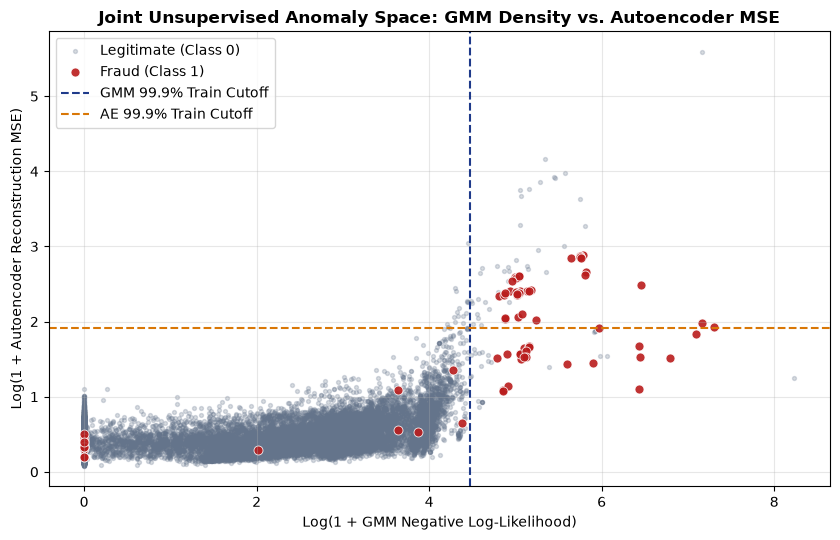

In [8]:
# === CELL 4: JOINT SCORE-SPACE VISUALIZATION & POST-HOC GROUND-TRUTH AUDIT ===
# Here we inspect how the purely unsupervised consensus pseudo-labels (99.9% train quantile)
# align with actual fraud without having used labels to set the thresholds.

y_test = test_df["Class"].values
gmm_p999 = generate_unsupervised_pseudo_labels(train_gmm_scores, test_gmm_scores, quantile=0.999)["pseudo_labels"]
ae_p999 = generate_unsupervised_pseudo_labels(train_ae_scores, test_ae_scores, quantile=0.999)["pseudo_labels"]
consensus_p999 = ((gmm_p999 == 1) & (ae_p999 == 1)).astype(int)

audit_rows = []
for name, preds in [
    ("GMM Pseudo-Labels (99.9% Train Quantile)", gmm_p999),
    ("Autoencoder Pseudo-Labels (99.9% Train Quantile)", ae_p999),
    ("Strict Consensus (Both Flagged = 1)", consensus_p999),
]:
    tp = int(((preds == 1) & (y_test == 1)).sum())
    fp = int(((preds == 1) & (y_test == 0)).sum())
    total_flagged = int(preds.sum())
    prec = tp / total_flagged if total_flagged > 0 else 0.0
    rec = tp / int(y_test.sum())
    audit_rows.append({
        "Unsupervised Labeling Rule": name,
        "Total Flagged": total_flagged,
        "True Frauds Caught (TP)": f"{tp} / {int(y_test.sum())}",
        "False Alarms (FP)": fp,
        "Precision": f"{prec*100:.2f}%",
        "Recall": f"{rec*100:.2f}%",
    })

audit_df = pd.DataFrame(audit_rows)
print("\n=== TABLE 3: POST-HOC AUDIT OF PURELY UNSUPERVISED 99.9% PSEUDO-LABELS ===")
print(audit_df.to_string(index=False))

# Plot Joint Unsupervised Anomaly Score Scatter (Log1p scaled for clarity)
plt.figure(figsize=(8.5, 5.5))
legit_mask = (y_test == 0)
fraud_mask = (y_test == 1)

plt.scatter(
    np.log1p( np.maximum(0, test_gmm_scores[legit_mask]) ),
    np.log1p( test_ae_scores[legit_mask] ),
    s=8, alpha=0.25, color="#64748b", label="Legitimate (Class 0)"
)
plt.scatter(
    np.log1p( np.maximum(0, test_gmm_scores[fraud_mask]) ),
    np.log1p( test_ae_scores[fraud_mask] ),
    s=42, alpha=0.90, color="#b91c1c", edgecolors="white", linewidth=0.6, label="Fraud (Class 1)"
)
plt.axvline(np.log1p(np.quantile(train_gmm_scores, 0.999)), color="#1e3a8a", linestyle="--", lw=1.5, label="GMM 99.9% Train Cutoff")
plt.axhline(np.log1p(np.quantile(train_ae_scores, 0.999)), color="#d97706", linestyle="--", lw=1.5, label="AE 99.9% Train Cutoff")
plt.title("Joint Unsupervised Anomaly Space: GMM Density vs. Autoencoder MSE", fontweight="bold")
plt.xlabel("Log(1 + GMM Negative Log-Likelihood)")
plt.ylabel("Log(1 + Autoencoder Reconstruction MSE)")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()